# GCSI Hourly Index Live Polling

## Integration guide: Global Commodity Sentiment Indices, hourly index

This notebook polls the **GCSI hourly index**, stores it in a local SQLite database, and builds a monitoring view
with a calibrated HIGH / NEUTRAL / LOW indicator. The same pattern, as three Docker services, is in
`app/live_index_polling/`.

### Output schema

| Field | Description |
|---|---|
| `ticker` | Commodity ticker, e.g. `BZ_COM` |
| `processed_at` | **End** of the hourly window (UTC), binned by when Permutable processed the headlines (when they became available) |
| `topic_name` | Topic label, `Sector::L1::L2` |
| `headline_count` | Distinct articles in the window |
| `sentiment_sum` | Sum of scores (−1 to +1 each) |
| `sentiment_std` | Sample standard deviation (0 when fewer than two headlines) |

`index_type` and `sentiment_type` are request parameters. The API does not return them, so this notebook writes both onto each row.

**Derived metrics**

```python
sentiment_avg = sentiment_sum / headline_count      # in [-1, +1]
```

### Rules this notebook follows

- `COMBINED` is the total of the three match types. **Never add `COMBINED` to the others.**
- Keep horizons separate. **Never add `sentiment_type`s together.**
- Topics are multi-label, so a ticker-level series built across topics is a **topic-weighted** average.
- Hours with no news are **omitted**, so rolling windows below are time-based (`'24h'`), not row-based.
- The newest bars can be **revised**. Every poll upserts, so a revised bar replaces the old one.

> **Disclaimer:** This notebook is provided for informational and research purposes only. Nothing here constitutes financial advice or a recommendation to buy, sell, or hold any asset. Sentiment scores are model outputs describing how news was judged at publication; they are not price forecasts.

In [ ]:
%pip install requests pandas numpy matplotlib seaborn

## Step 1: Configuration

The API client, storage, metrics and chart helpers live in [`../utils`](../utils/), shared by every notebook in this folder. Open them to see how each step works.

In [2]:
import sys
import time
from datetime import datetime, timedelta, timezone
from pathlib import Path

sys.path.insert(0, str(Path('..').resolve()))  # notebooks/, for the shared utils package
from utils import charts, metrics
from utils.api import GcsiClient, to_index_frame
from utils.store import IndexStore

# ── Poll configuration ─────────────────────────────────────────────────────
TICKERS = ['BZ_COM', 'QO_COM', 'ZC_COM', 'EUA_COM']        # Brent, gold, corn, EU carbon
INDEX_TYPES = ['COMBINED']                                   # add EXPLICIT etc. for the breakdown in Step 6
SENTIMENT_TYPES = ['short_term', 'medium_term', 'long_term']
POLL_INTERVAL_SECONDS = 900
BACKFILL_DAYS = 7
DB_PATH = 'gcsi_index_nb.db'

# ── Indicator ──────────────────────────────────────────────────────────────
SMOOTHING_WINDOW = '24h'      # time-based, so missing hours are handled correctly
MIN_HEADLINES = 5             # fewer topic-links than this in the window → no reading
THRESHOLD_MODE = 'percentile' # 'percentile' (calibrated from the data) or 'fixed'
UPPER_PCT, LOWER_PCT = 0.90, 0.10
FIXED_UPPER, FIXED_LOWER = 0.15, -0.15

client = GcsiClient()         # API_KEY from the environment or a .env file, otherwise a prompt
store = IndexStore(DB_PATH)   # upserts, so a revised bar replaces the earlier version of the same hour

calls = len(TICKERS) * len(INDEX_TYPES) * len(SENTIMENT_TYPES)
print(f'{calls} live requests per poll cycle; every request counts against your monthly quota.')

12 live requests per poll cycle; every request counts against your monthly quota.


## Step 2: Dry run (single live poll)

Check connectivity and the response shape before backfilling.

In [3]:
sample = client.index_live(TICKERS[0], INDEX_TYPES[0], SENTIMENT_TYPES[0])
print(f'{len(sample)} records for {TICKERS[0]} / {INDEX_TYPES[0]} / {SENTIMENT_TYPES[0]}')
if sample:
    print('Fields:', sorted(sample[0]))
    frame = to_index_frame(sample)
    frame['sentiment_avg'] = frame['sentiment_sum'] / frame['headline_count']
    display(frame.sort_values('processed_at').tail(10))

420 records for BZ_COM / COMBINED / short_term
Fields: ['headline_count', 'index_type', 'processed_at', 'sentiment_abs_sum', 'sentiment_std', 'sentiment_sum', 'sentiment_type', 'ticker', 'topic_id', 'topic_name']


,ticker,topic_name,topic_id,processed_at,headline_count,sentiment_sum,sentiment_abs_sum,sentiment_std,index_type,sentiment_type,sentiment_avg
12,BZ_COM,Energy::Macro::Policy & Regulation,db5adcb1-2453-542a-aa28-4cb4d7f18ad7,2026-11-10 15:00:00+00:00,4,-0.424,0.424,0.106,COMBINED,short_term,-0.106000
9,BZ_COM,Energy::Supply::Disruptions,91e6e966-e376-5a3b-a547-e9c84e09279a,2026-11-10 15:00:00+00:00,16,4.151,4.395,0.138,COMBINED,short_term,0.259437
10,BZ_COM,Energy::Macro::Conflict,a05ae7bf-b955-5db5-929b-467e0d1ccb63,2026-11-10 15:00:00+00:00,67,12.452,16.626,0.224,COMBINED,short_term,0.185851
11,BZ_COM,Energy::Market::Forecasts,d905061b-2eed-53c8-a507-6ce8a834cd8b,2026-11-10 15:00:00+00:00,5,-0.145,0.269,0.080,COMBINED,short_term,-0.029000
13,BZ_COM,Energy::Demand::Global Consumption,df8ccf67-3f01-569c-b1a4-0aea06831153,2026-11-10 15:00:00+00:00,2,0.214,0.756,0.535,COMBINED,short_term,0.107000
14,BZ_COM,Energy::Macro::Economy & Central Banks,e7fa2e75-23b3-5f13-9866-b40500c219ba,2026-11-10 15:00:00+00:00,95,-3.311,5.303,0.081,COMBINED,short_term,-0.034853
15,BZ_COM,Energy::Demand::Industrial & Power,eceb110b-358f-5e01-8f0d-06cb80bdd8c1,2026-11-10 15:00:00+00:00,1,0.131,0.131,0.000,COMBINED,short_term,0.131000
16,BZ_COM,Energy::Macro::Producer Policy,f3851f6d-1103-5f49-a4b1-d59a80f8bfb6,2026-11-10 15:00:00+00:00,1,0.220,0.220,0.000,COMBINED,short_term,0.220000
8,BZ_COM,Energy::Supply::Infrastructure & Logistics,7b82e680-15aa-5eb4-a28c-166d87317819,2026-11-10 15:00:00+00:00,19,3.642,4.062,0.103,COMBINED,short_term,0.191684
0,BZ_COM,Energy::Demand::Transportation,0ee7138c-7607-5497-a7b8-7b8342b887bc,2026-11-10 15:00:00+00:00,3,0.207,0.495,0.185,COMBINED,short_term,0.069000


## Step 3: Historical backfill

Fills the database with the last `BACKFILL_DAYS` so the charts have context. Historical requests page with
`next_token`. Running it again is safe, because rows are upserted.

In [4]:
def poll_once(fetch) -> int:
    """Call fetch(ticker, index_type, sentiment_type) for every combination and upsert the rows."""
    total = 0
    for ticker in TICKERS:
        for index_type in INDEX_TYPES:
            for sentiment_type in SENTIMENT_TYPES:
                try:
                    total += store.upsert(fetch(ticker, index_type, sentiment_type))
                except PermissionError:
                    raise
                except Exception as exc:
                    print(f'  {ticker}/{index_type}/{sentiment_type}: ERROR {exc}')
    return total


RUN_BACKFILL = True

if RUN_BACKFILL:
    start = (datetime.now(timezone.utc) - timedelta(days=BACKFILL_DAYS)).date()
    n = poll_once(lambda t, i, s: client.index_history(t, start, index_type=i, sentiment_type=s))
    print(f'Backfill complete: {n:,} rows upserted.')

Backfill complete: 19,272 rows upserted.


## Step 4: Ticker-level sentiment by horizon

Rows for every topic are added per hour (topic-weighted). A 24-hour, time-based window then gives a weighted
rolling average: `Σ sentiment_sum / Σ headline_count` over the window. This is not a mean of hourly averages,
which would give a quiet hour the same weight as a busy one.

17,280 stored rows → 1,662 ticker-hours

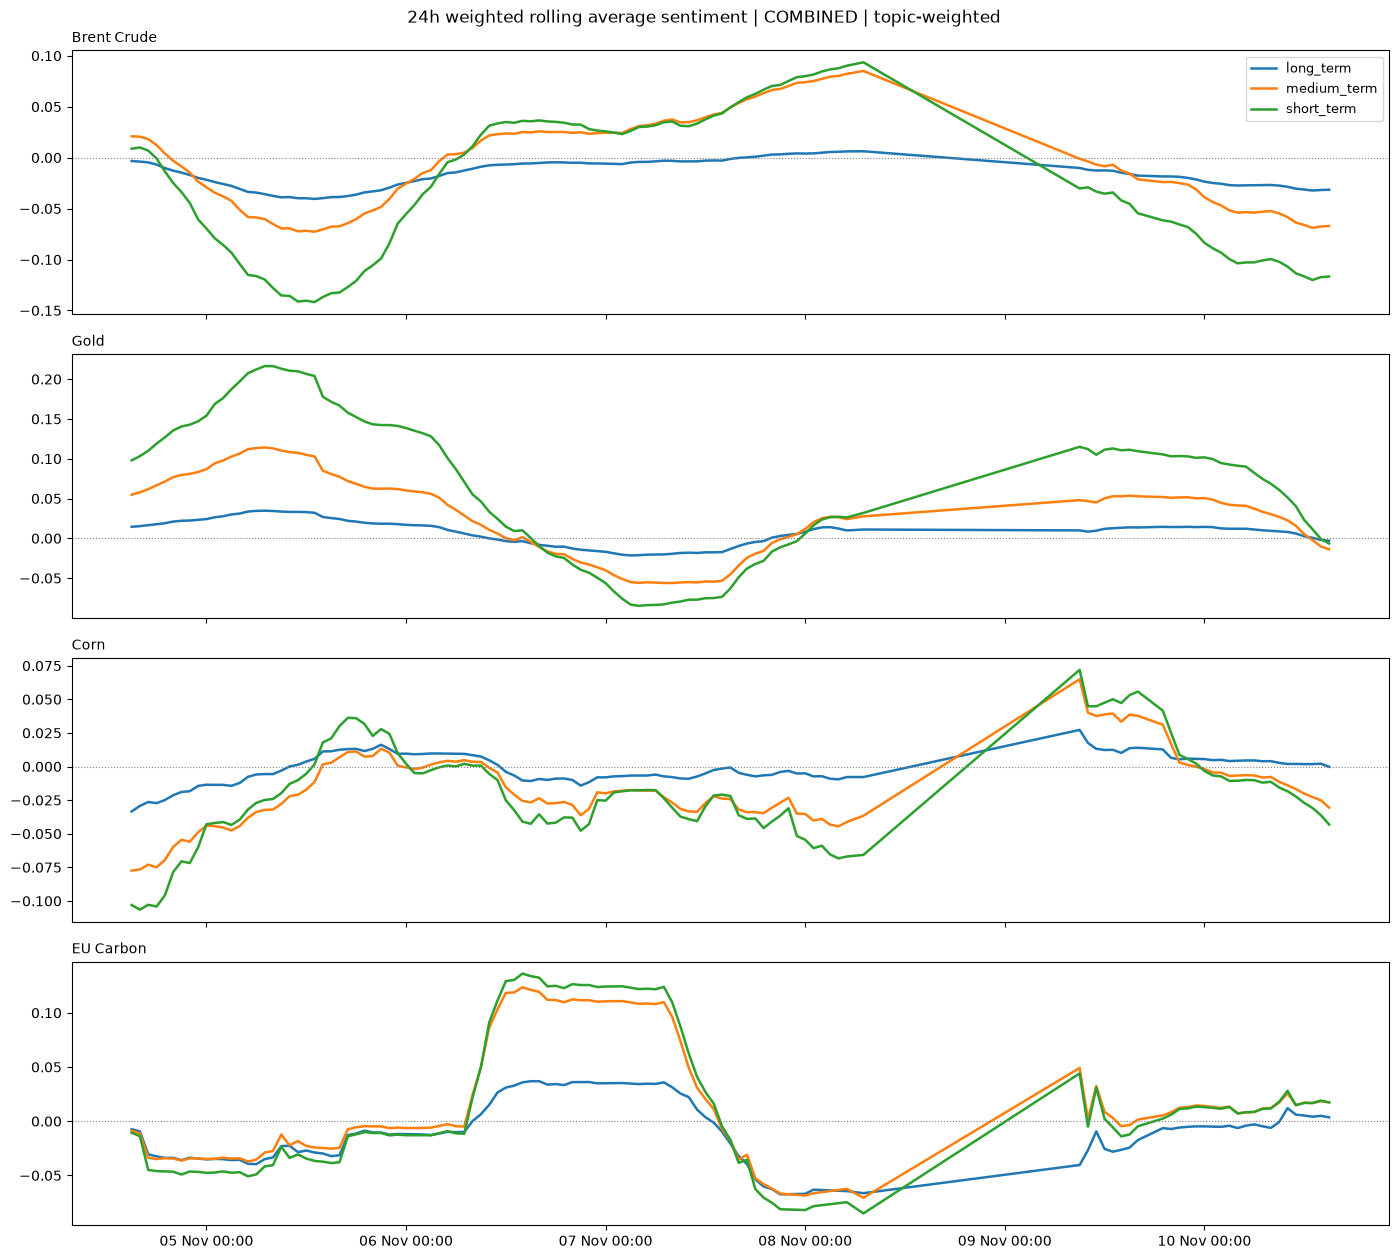

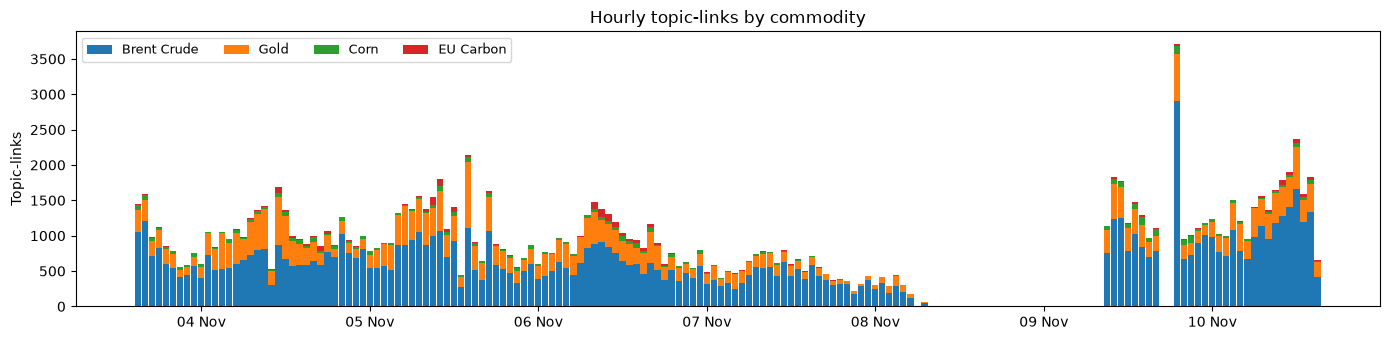

In [5]:
df = store.load(hours=24 * BACKFILL_DAYS)
series = metrics.ticker_series(df, SMOOTHING_WINDOW, MIN_HEADLINES)
tickers = [t for t in TICKERS if t in set(series['ticker'])]
print(f'{len(df):,} stored rows → {len(series):,} ticker-hours')

if series.empty:
    print('No data yet: run the backfill above.')
else:
    charts.smoothed_by_ticker(series, tickers,
                              f'{SMOOTHING_WINDOW} weighted rolling average sentiment | COMBINED | topic-weighted')
    charts.volume_by_ticker(series, tickers)

## Step 5: Calibrated indicator

A fixed threshold that suits one commodity can misfire on another, so by default
the thresholds come from the distribution of each ticker's own smoothed series (`THRESHOLD_MODE = 'percentile'`).
With only a week of history the percentiles are a rough guide. For production, calibrate on a longer history:
the historical route serves up to 90 days per request.

,ticker,sentiment_type,processed_at,sentiment_smooth,window_count,lower,upper,indicator
0,BZ_COM,long_term,2026-11-10 15:00:00+00:00,-0.031,23528.0,-0.035,0.001,NEUTRAL
1,BZ_COM,medium_term,2026-11-10 15:00:00+00:00,-0.067,23528.0,-0.066,0.061,LOW
2,BZ_COM,short_term,2026-11-10 15:00:00+00:00,-0.117,23528.0,-0.120,0.064,NEUTRAL
3,EUA_COM,long_term,2026-11-10 15:00:00+00:00,0.004,431.0,-0.039,0.034,NEUTRAL
4,EUA_COM,medium_term,2026-11-10 15:00:00+00:00,0.017,431.0,-0.035,0.111,NEUTRAL
5,EUA_COM,short_term,2026-11-10 15:00:00+00:00,0.017,431.0,-0.048,0.124,NEUTRAL
6,QO_COM,long_term,2026-11-10 15:00:00+00:00,-0.003,7169.0,-0.018,0.027,NEUTRAL
7,QO_COM,medium_term,2026-11-10 15:00:00+00:00,-0.014,7169.0,-0.052,0.096,NEUTRAL
8,QO_COM,short_term,2026-11-10 15:00:00+00:00,-0.007,7169.0,-0.074,0.177,NEUTRAL
9,ZC_COM,long_term,2026-11-10 15:00:00+00:00,-0.000,942.0,-0.014,0.012,NEUTRAL


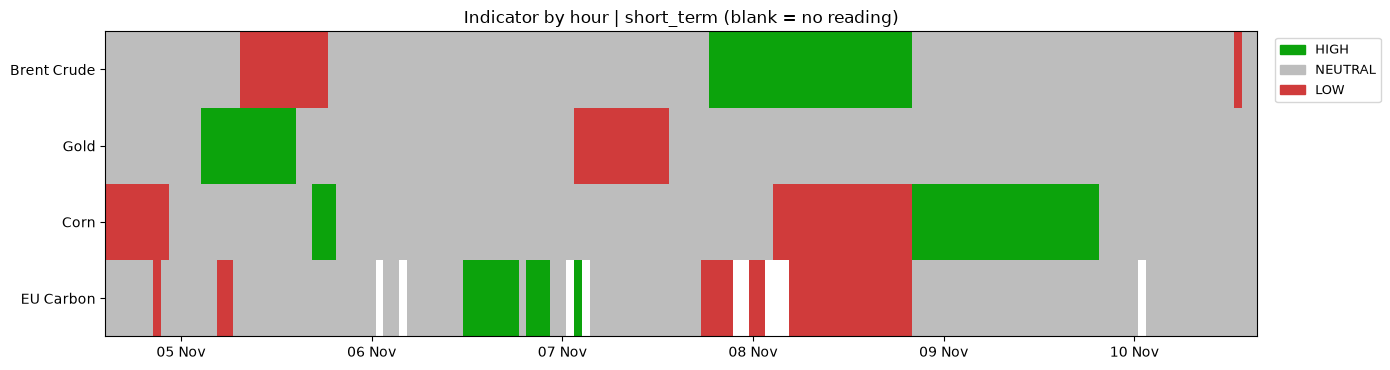

In [6]:
if not series.empty:
    series = metrics.add_indicator(series, THRESHOLD_MODE, UPPER_PCT, LOWER_PCT, FIXED_UPPER, FIXED_LOWER)
    latest = series.sort_values('processed_at').groupby(['ticker', 'sentiment_type']).last().reset_index()
    display(latest[['ticker', 'sentiment_type', 'processed_at', 'sentiment_smooth', 'window_count',
                    'lower', 'upper', 'indicator']].round({'sentiment_smooth': 3, 'lower': 3, 'upper': 3}))
    charts.indicator_timeline(series, tickers)

## Step 6: Index-type breakdown (optional)

Add `'EXPLICIT'`, `'RELATED_ENTITY'` and `'MACROECONOMIC'` to `INDEX_TYPES`, then run the backfill again. This
shows whether a move came from news about the commodity itself, from linked entities, or from the macro
backdrop. Each line is its own series, and `COMBINED` is their volume-weighted blend.

In [7]:
lines = {}
for index_type in ['EXPLICIT', 'RELATED_ENTITY', 'MACROECONOMIC', 'COMBINED']:
    rows = store.load(hours=24 * BACKFILL_DAYS, index_type=index_type)
    rows = rows[(rows['ticker'] == TICKERS[0]) & (rows['sentiment_type'] == 'short_term')]
    if not rows.empty:
        lines[index_type] = metrics.ticker_series(rows, SMOOTHING_WINDOW, MIN_HEADLINES)

if len(lines) < 2:
    print('Only one index type stored: add more to INDEX_TYPES and run the backfill to see the breakdown.')
else:
    charts.smoothed_lines(lines, f'{charts.ticker_label(TICKERS[0])} | short_term | '
                                 f'{SMOOTHING_WINDOW} weighted average by index type')

Only one index type stored: add more to INDEX_TYPES and run the backfill to see the breakdown.


## Step 7: Topic heatmap

Which topics drove the short-term reading over the last few days? Cells with fewer than `MIN_HEADLINES` topic-links
are left blank, because an average of one or two headlines is mostly noise.

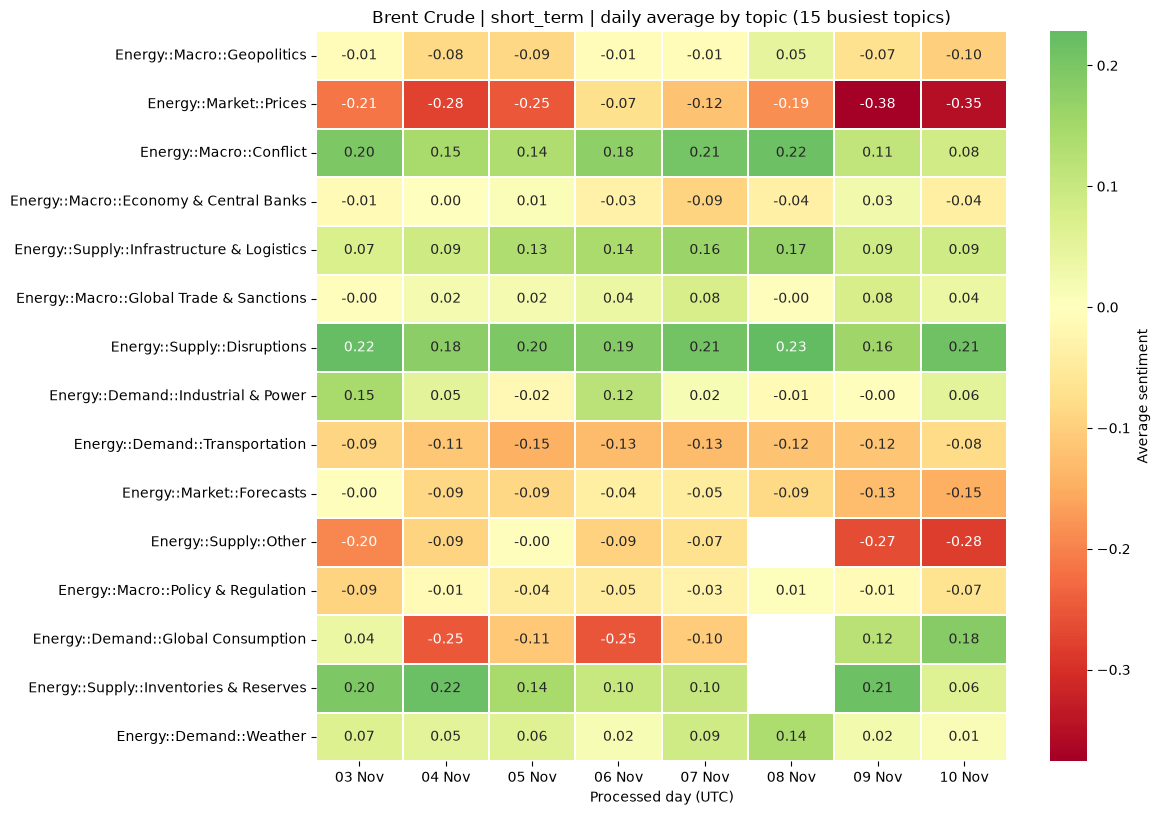

In [8]:
if not df.empty:
    rows = df[(df['ticker'] == TICKERS[0]) & (df['sentiment_type'] == 'short_term')]
    grid = metrics.daily_topic_average(rows, MIN_HEADLINES, top=15)
    charts.topic_heatmap(grid, f'{charts.ticker_label(TICKERS[0])} | short_term | daily average by topic '
                               '(15 busiest topics)', xlabel='Processed day (UTC)', annotate=True)

## Step 8: Live polling loop

Polls every `POLL_INTERVAL_SECONDS`. Each cycle upserts the latest bars, including revisions to recent hours.
Stop it with the Jupyter interrupt button.

In [9]:
RUN_POLLING_LOOP = False

if RUN_POLLING_LOOP:
    cycle = 0
    while True:
        cycle += 1
        started = datetime.now(timezone.utc)
        n = poll_once(client.index_live)
        elapsed = (datetime.now(timezone.utc) - started).total_seconds()
        print(f'[{cycle}] {started:%H:%M:%S} UTC: {n} rows upserted in {elapsed:.1f}s')
        time.sleep(max(0, POLL_INTERVAL_SECONDS - elapsed))
else:
    print('Polling loop disabled: set RUN_POLLING_LOOP = True to start it.')

Polling loop disabled: set RUN_POLLING_LOOP = True to start it.
